# 03 · Dense NN, vanilla RNN, LSTM y BiLSTM (extra) — Sentiment analysis (GoEmotions)
**Responsable:** Camila · Usa el split ya generado (`data/processed/train.csv` y `test.csv`, 800/200).
El test **solo** se usa para la evaluación final; el tuning se hace con validación cruzada dentro de train.

In [2]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.train import (load_tokens, grid_search, final_runs, ALL_MODEL_NAMES, GRID, FIXED, log, SEED)
from src.evaluate import METRICS_DIR

FIG_DIR = ROOT / "outputs" / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
QUICK = False   # True = grid reducido para probar que todo corre (unos minutos menos)

## 1. Datos

In [3]:
tok_tr, y_tr, tok_te, y_te = load_tokens("clean")
lens = [len(t) for t in tok_tr]
print(f"train={len(tok_tr)} test={len(tok_te)} | balance train={np.bincount(y_tr)} test={np.bincount(y_te)}")
print(f"tokens por comentario (clean): media={np.mean(lens):.1f} máx={max(lens)} vacíos={sum(l==0 for l in lens)}")

train=800 test=200 | balance train=[400 400] test=[100 100]
tokens por comentario (clean): media=7.3 máx=21 vacíos=0


## 2. Tuning (CV estratificada de 3 folds sobre train)
Se exploran `hidden`, `batch_size` y `lr`; el número de `epochs` lo decide el early stopping (se reporta la época media óptima).
`emb_dim=64` y `dropout=0.5` quedan fijos para mantener el grid manejable.

In [4]:
grid = {"hidden":[32,128], "batch_size":[32], "lr":[1e-3]} if QUICK else GRID
search = {}
for name in ALL_MODEL_NAMES:
    search[name] = grid_search(name, tok_tr, y_tr, grid=grid)
    search[name].to_csv(ROOT/"outputs"/"metrics"/f"gridsearch_{name}.csv", index=False)
    print("\n==", name); display(search[name].head(5).round(4))

[2026-11-21 20:41:39] [dense] grid search: 18 configuraciones x 3 folds
[2026-11-21 20:41:44] [dense] 1/18 {'hidden': 32, 'batch_size': 16, 'lr': 0.001} val_acc=0.6113 best_epoch=9.7 (5.8s)
[2026-11-21 20:41:46] [dense] 2/18 {'hidden': 32, 'batch_size': 16, 'lr': 0.003} val_acc=0.5913 best_epoch=3.0 (1.4s)
[2026-11-21 20:41:47] [dense] 3/18 {'hidden': 32, 'batch_size': 32, 'lr': 0.001} val_acc=0.6051 best_epoch=13.0 (1.6s)
[2026-11-21 20:41:48] [dense] 4/18 {'hidden': 32, 'batch_size': 32, 'lr': 0.003} val_acc=0.5901 best_epoch=4.7 (0.9s)
[2026-11-21 20:41:50] [dense] 5/18 {'hidden': 32, 'batch_size': 64, 'lr': 0.001} val_acc=0.6038 best_epoch=19.0 (1.4s)
[2026-11-21 20:41:50] [dense] 6/18 {'hidden': 32, 'batch_size': 64, 'lr': 0.003} val_acc=0.6151 best_epoch=7.3 (0.8s)
[2026-11-21 20:41:52] [dense] 7/18 {'hidden': 64, 'batch_size': 16, 'lr': 0.001} val_acc=0.5814 best_epoch=5.7 (1.8s)
[2026-11-21 20:41:54] [dense] 8/18 {'hidden': 64, 'batch_size': 16, 'lr': 0.003} val_acc=0.5764 best

,hidden,batch_size,lr,val_acc,val_acc_std,val_f1,best_epoch
0,32,64,0.003,0.6151,0.0500,0.6786,7.3333
1,32,16,0.001,0.6113,0.0485,0.6742,9.6667
2,32,32,0.001,0.6051,0.0364,0.6714,13.0000
3,32,64,0.001,0.6038,0.0420,0.6717,19.0000
4,32,16,0.003,0.5913,0.0653,0.6688,3.0000


[2026-11-21 20:42:03] [vanilla_rnn] grid search: 18 configuraciones x 3 folds
[2026-11-21 20:42:07] [vanilla_rnn] 1/18 {'hidden': 32, 'batch_size': 16, 'lr': 0.001} val_acc=0.5250 best_epoch=3.7 (3.4s)
[2026-11-21 20:42:09] [vanilla_rnn] 2/18 {'hidden': 32, 'batch_size': 16, 'lr': 0.003} val_acc=0.5312 best_epoch=1.7 (2.7s)
[2026-11-21 20:42:11] [vanilla_rnn] 3/18 {'hidden': 32, 'batch_size': 32, 'lr': 0.001} val_acc=0.5075 best_epoch=4.3 (2.1s)
[2026-11-21 20:42:13] [vanilla_rnn] 4/18 {'hidden': 32, 'batch_size': 32, 'lr': 0.003} val_acc=0.5200 best_epoch=1.7 (1.7s)
[2026-11-21 20:42:15] [vanilla_rnn] 5/18 {'hidden': 32, 'batch_size': 64, 'lr': 0.001} val_acc=0.5162 best_epoch=6.7 (1.6s)
[2026-11-21 20:42:16] [vanilla_rnn] 6/18 {'hidden': 32, 'batch_size': 64, 'lr': 0.003} val_acc=0.5413 best_epoch=3.3 (1.2s)
[2026-11-21 20:42:18] [vanilla_rnn] 7/18 {'hidden': 64, 'batch_size': 16, 'lr': 0.001} val_acc=0.5350 best_epoch=1.3 (2.6s)
[2026-11-21 20:42:21] [vanilla_rnn] 8/18 {'hidden': 64

,hidden,batch_size,lr,val_acc,val_acc_std,val_f1,best_epoch
0,128,16,0.003,0.5425,0.0326,0.5293,1.0000
1,32,64,0.003,0.5413,0.0131,0.5518,3.3333
2,64,64,0.001,0.5363,0.0085,0.5523,3.6667
3,128,64,0.003,0.5350,0.0282,0.5174,1.3333
4,64,16,0.001,0.5350,0.0207,0.5434,1.3333


[2026-11-21 20:42:39] [lstm] grid search: 18 configuraciones x 3 folds
[2026-11-21 20:42:46] [lstm] 1/18 {'hidden': 32, 'batch_size': 16, 'lr': 0.001} val_acc=0.6613 best_epoch=7.0 (7.7s)
[2026-11-21 20:42:51] [lstm] 2/18 {'hidden': 32, 'batch_size': 16, 'lr': 0.003} val_acc=0.6475 best_epoch=3.0 (5.0s)
[2026-11-21 20:42:57] [lstm] 3/18 {'hidden': 32, 'batch_size': 32, 'lr': 0.001} val_acc=0.6475 best_epoch=9.7 (5.5s)
[2026-11-21 20:43:01] [lstm] 4/18 {'hidden': 32, 'batch_size': 32, 'lr': 0.003} val_acc=0.6663 best_epoch=4.3 (3.6s)
[2026-11-21 20:43:05] [lstm] 5/18 {'hidden': 32, 'batch_size': 64, 'lr': 0.001} val_acc=0.6500 best_epoch=14.7 (4.6s)
[2026-11-21 20:43:08] [lstm] 6/18 {'hidden': 32, 'batch_size': 64, 'lr': 0.003} val_acc=0.6638 best_epoch=6.3 (2.6s)
[2026-11-21 20:43:14] [lstm] 7/18 {'hidden': 64, 'batch_size': 16, 'lr': 0.001} val_acc=0.6126 best_epoch=4.0 (6.2s)
[2026-11-21 20:43:19] [lstm] 8/18 {'hidden': 64, 'batch_size': 16, 'lr': 0.003} val_acc=0.5913 best_epoch=2.0

,hidden,batch_size,lr,val_acc,val_acc_std,val_f1,best_epoch
0,32,32,0.003,0.6663,0.0431,0.6699,4.3333
1,32,64,0.003,0.6638,0.0533,0.6734,6.3333
2,32,16,0.001,0.6613,0.0538,0.6754,7.0000
3,32,64,0.001,0.6500,0.0496,0.6527,14.6667
4,32,16,0.003,0.6475,0.0630,0.6575,3.0000


[2026-11-21 20:43:58] [bilstm] grid search: 18 configuraciones x 3 folds
[2026-11-21 20:44:10] [bilstm] 1/18 {'hidden': 32, 'batch_size': 16, 'lr': 0.001} val_acc=0.6275 best_epoch=5.7 (11.7s)
[2026-11-21 20:44:17] [bilstm] 2/18 {'hidden': 32, 'batch_size': 16, 'lr': 0.003} val_acc=0.6250 best_epoch=2.0 (7.5s)
[2026-11-21 20:44:26] [bilstm] 3/18 {'hidden': 32, 'batch_size': 32, 'lr': 0.001} val_acc=0.6263 best_epoch=8.3 (8.3s)
[2026-11-21 20:44:31] [bilstm] 4/18 {'hidden': 32, 'batch_size': 32, 'lr': 0.003} val_acc=0.6263 best_epoch=3.3 (5.3s)
[2026-11-21 20:44:38] [bilstm] 5/18 {'hidden': 32, 'batch_size': 64, 'lr': 0.001} val_acc=0.6325 best_epoch=12.3 (6.7s)
[2026-11-21 20:44:41] [bilstm] 6/18 {'hidden': 32, 'batch_size': 64, 'lr': 0.003} val_acc=0.6325 best_epoch=5.0 (3.9s)
[2026-11-21 20:44:51] [bilstm] 7/18 {'hidden': 64, 'batch_size': 16, 'lr': 0.001} val_acc=0.5938 best_epoch=3.3 (9.8s)
[2026-11-21 20:44:59] [bilstm] 8/18 {'hidden': 64, 'batch_size': 16, 'lr': 0.003} val_acc=0.

,hidden,batch_size,lr,val_acc,val_acc_std,val_f1,best_epoch
0,32,64,0.003,0.6325,0.0104,0.6859,5.0000
1,32,64,0.001,0.6325,0.0075,0.6887,12.3333
2,32,16,0.001,0.6275,0.0046,0.6820,5.6667
3,32,32,0.003,0.6263,0.0132,0.6801,3.3333
4,32,32,0.001,0.6263,0.0117,0.6846,8.3333


## 3. Evaluación final en test (5 semillas, mejores hiperparámetros)

In [5]:
final, runs = {}, {}
for name in ALL_MODEL_NAMES:
    best = search[name].iloc[0]
    params = {**FIXED, "hidden": int(best.hidden), "batch_size": int(best.batch_size), "lr": float(best.lr)}
    final[name], runs[name] = final_runs(name, tok_tr, y_tr, tok_te, y_te, params)
    print(name, params)

[2026-11-21 20:46:13] [dense] seed=42 best_epoch=8 test_acc=0.7350 f1=0.6971 kappa=0.4700 (0.3s)
[2026-11-21 20:46:13] [dense] seed=43 best_epoch=6 test_acc=0.5700 f1=0.6641 kappa=0.1400 (0.3s)
[2026-11-21 20:46:14] [dense] seed=44 best_epoch=8 test_acc=0.6300 f1=0.5747 kappa=0.2600 (0.3s)
[2026-11-21 20:46:14] [dense] seed=45 best_epoch=6 test_acc=0.6750 f1=0.6061 kappa=0.3500 (0.3s)
[2026-11-21 20:46:14] [dense] seed=46 best_epoch=8 test_acc=0.7250 f1=0.6707 kappa=0.4500 (0.3s)
[2026-11-21 20:46:14] [dense] MEDIA 5 semillas: accuracy=0.6670±0.0614 precision=0.7278±0.1067 recall=0.6040±0.1297 f1=0.6425±0.0451 kappa=0.3340±0.1227
dense {'emb_dim': 64, 'dropout': 0.5, 'hidden': 32, 'batch_size': 64, 'lr': 0.003}
[2026-11-21 20:46:15] [vanilla_rnn] seed=42 best_epoch=1 test_acc=0.5600 f1=0.6271 kappa=0.1200 (1.1s)
[2026-11-21 20:46:17] [vanilla_rnn] seed=43 best_epoch=1 test_acc=0.5050 f1=0.6526 kappa=0.0100 (1.3s)
[2026-11-21 20:46:18] [vanilla_rnn] seed=44 best_epoch=1 test_acc=0.5800 

## 4. Tabla comparativa (incluye baseline)

In [6]:
rows = []
for f in ["baseline_dummy"] + ALL_MODEL_NAMES:
    d = json.loads((METRICS_DIR/f"{f}.json").read_text())
    r = {"model": d["model"]}
    for k in ["accuracy","precision","recall","f1","kappa"]:
        s = d.get("std", {}).get(k)
        r[k] = f"{d[k]:.3f}" + (f" ± {s:.3f}" if s is not None else "")
    r["params"] = d.get("n_params", "-"); r["sec/run"] = d.get("train_seconds_per_run", "-")
    rows.append(r)
table = pd.DataFrame(rows); table.to_csv(METRICS_DIR/"comparison.csv", index=False)
table

,model,accuracy,precision,recall,f1,kappa,params,sec/run
0,baseline_dummy,0.500,0.500,0.510,0.505,0.000,-,-
1,dense,0.667 ± 0.061,0.728 ± 0.107,0.604 ± 0.130,0.642 ± 0.045,0.334 ± 0.123,144065,0.3
2,vanilla_rnn,0.577 ± 0.044,0.577 ± 0.053,0.700 ± 0.162,0.617 ± 0.051,0.154 ± 0.088,166913,1.2
3,lstm,0.628 ± 0.055,0.623 ± 0.057,0.704 ± 0.070,0.655 ± 0.018,0.256 ± 0.110,154529,1.5
4,bilstm,0.640 ± 0.070,0.664 ± 0.080,0.656 ± 0.169,0.638 ± 0.078,0.280 ± 0.139,167105,1.6


## 5. Figuras

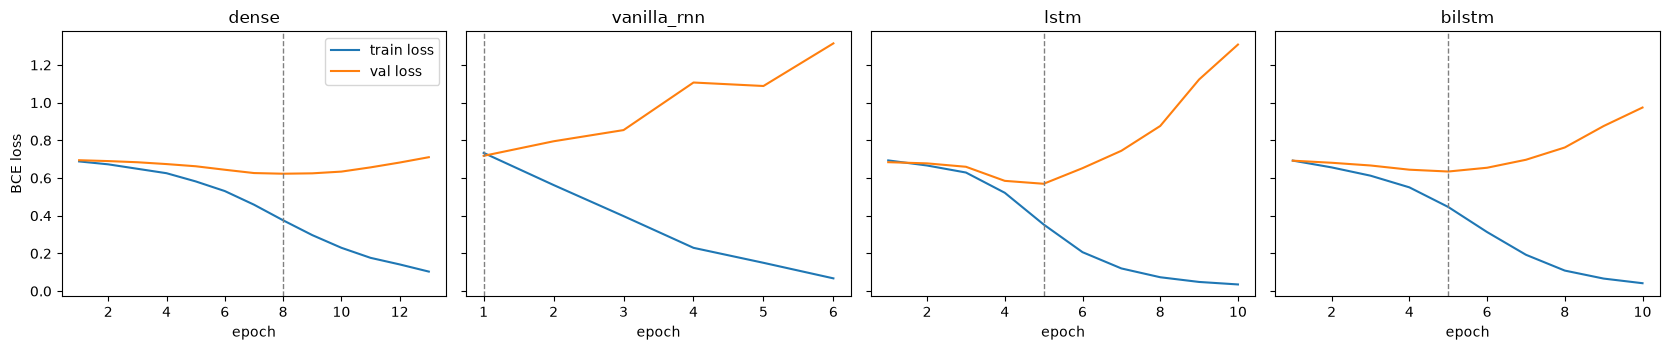

In [7]:
# Curvas de entrenamiento (semilla 42)
fig, ax = plt.subplots(1, len(ALL_MODEL_NAMES), figsize=(4.2*len(ALL_MODEL_NAMES), 3.6), sharey=True)
for a, name in zip(ax, ALL_MODEL_NAMES):
    h = pd.DataFrame(runs[name][0]["history"])
    a.plot(h.epoch, h.train_loss, label="train loss"); a.plot(h.epoch, h.val_loss, label="val loss")
    a.axvline(runs[name][0]["best_epoch"], ls="--", c="gray", lw=1)
    a.set_title(name); a.set_xlabel("epoch")
ax[0].set_ylabel("BCE loss"); ax[0].legend(); plt.tight_layout()
plt.savefig(FIG_DIR/"nn_training_curves.png", dpi=200); plt.show()

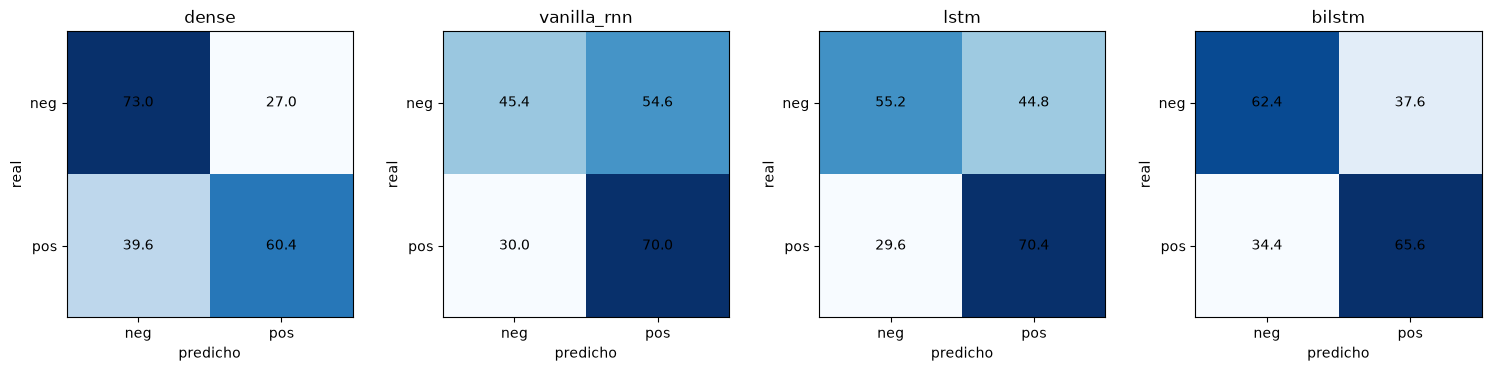

In [8]:
# Matrices de confusión (promedio de semillas)
fig, ax = plt.subplots(1, len(ALL_MODEL_NAMES), figsize=(3.8*len(ALL_MODEL_NAMES), 3.6))
for a, name in zip(ax, ALL_MODEL_NAMES):
    cm = np.array(final[name]["confusion_matrix"])
    a.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2): a.text(j, i, f"{cm[i,j]:.1f}", ha="center", va="center")
    a.set_xticks([0,1], ["neg","pos"]); a.set_yticks([0,1], ["neg","pos"])
    a.set_title(name); a.set_xlabel("predicho"); a.set_ylabel("real")
plt.tight_layout(); plt.savefig(FIG_DIR/"nn_confusion_matrices.png", dpi=200); plt.show()

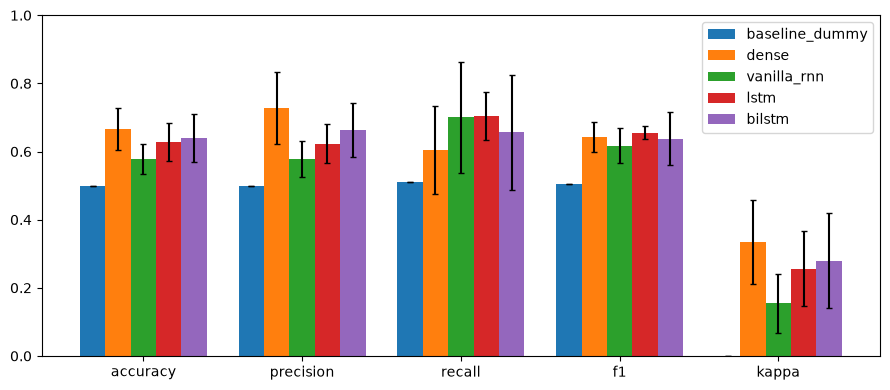

In [9]:
# Comparación de métricas con barras de error (baseline sin error)
mets = ["accuracy","precision","recall","f1","kappa"]
names = ["baseline_dummy"] + ALL_MODEL_NAMES
data = {n: json.loads((METRICS_DIR/f"{n}.json").read_text()) for n in names}
x = np.arange(len(mets)); w = 0.8/len(names)
fig, ax = plt.subplots(figsize=(9, 4))
for i, n in enumerate(names):
    ax.bar(x + (i-(len(names)-1)/2)*w, [data[n][m] for m in mets], w, label=n,
           yerr=[data[n].get("std", {}).get(m, 0) for m in mets], capsize=2)
ax.set_xticks(x, mets); ax.set_ylim(0, 1); ax.legend(); plt.tight_layout()
plt.savefig(FIG_DIR/"nn_metrics_comparison.png", dpi=200); plt.show()

## 6. ¿ayuda conservar las stopwords?
El pipeline del equipo elimina stopwords, pero las RNN/LSTM aprovechan el orden y los conectores. Se reentrenan con `text_mode="full"` y los mismos hiperparámetros.

In [10]:
ftr, fy_tr, fte, fy_te = load_tokens("full")
for name in ["vanilla_rnn", "lstm", "bilstm"]:
    p = final[name]["params"]
    final_runs(name, ftr, fy_tr, fte, fy_te, p, save_name=f"{name}_full")

[2026-11-21 20:51:06] [vanilla_rnn_full] seed=42 best_epoch=1 test_acc=0.5550 f1=0.5528 kappa=0.1100 (1.5s)
[2026-11-21 20:51:08] [vanilla_rnn_full] seed=43 best_epoch=1 test_acc=0.5800 f1=0.6348 kappa=0.1600 (1.7s)
[2026-11-21 20:51:10] [vanilla_rnn_full] seed=44 best_epoch=1 test_acc=0.5350 f1=0.6009 kappa=0.0700 (1.5s)
[2026-11-21 20:51:11] [vanilla_rnn_full] seed=45 best_epoch=1 test_acc=0.5650 f1=0.6234 kappa=0.1300 (1.4s)
[2026-11-21 20:51:12] [vanilla_rnn_full] seed=46 best_epoch=1 test_acc=0.5500 f1=0.5833 kappa=0.1000 (1.4s)
[2026-11-21 20:51:12] [vanilla_rnn_full] MEDIA 5 semillas: accuracy=0.5570±0.0150 precision=0.5472±0.0121 recall=0.6660±0.0677 f1=0.5990±0.0292 kappa=0.1140±0.0301
[2026-11-21 20:51:15] [lstm_full] seed=42 best_epoch=5 test_acc=0.6500 f1=0.6465 kappa=0.3000 (2.2s)
[2026-11-21 20:51:17] [lstm_full] seed=43 best_epoch=4 test_acc=0.6450 f1=0.6603 kappa=0.2900 (2.0s)
[2026-11-21 20:51:19] [lstm_full] seed=44 best_epoch=5 test_acc=0.6650 f1=0.6794 kappa=0.3300 